# Classification Model

The objective of this analysis is to develop classification models to predict offensive play selection in college football.

Target variable: offensive play type (pass or rush)
Models: Null model, logistic regression, random forest classifier, neural network classifier

The following classification models will be developed:
- Null model
- Logistic Regression
- Lasso Logistic Regression
- Random Forest Classifier
- Neural Network Classifier

- Feature selection: the models will use features selected during EDA based on missing values, variance, and corelation
- Data leakage: only information available before the snap will be used as model input. Post-play outcomes such as `yardsGained` and `ppa` are excluded
- Train/test split: games are separated into training and testing set to prevent plays from the same game from appearing in both sets
- Metrics: model performance will be compared using accuracy, precision, recall, F1 score, and ROC AUC.

In [67]:
# Import statements
import numpy as np
import pandas as pd
import json
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
RANDOM_STATE = 42
TARGET = "is_pass"

## Load data

In [68]:
# Load modeling dataset
df = pd.read_csv("../data/processed/model_df.csv")

# Load classification feature selections from EDA
with open("../data/processed/classification_feature_lists_after_eda.json") as f:
    feature_info = json.load(f)["classification"]

In [69]:
# Selected classification features
features = feature_info["features"]

# Feature groups
numeric_features = feature_info["numeric"]
categorical_features = feature_info["categorical"]
binary_features = feature_info["binary"]

print(f"Total features: {len(features)}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")
print(f"Binary features: {len(binary_features)}")
print(f"Features: ", features)

Total features: 24
Numeric features: 11
Categorical features: 2
Binary features: 11
Features:  ['distance', 'yardsToGoal', 'sec_left_half', 'sec_left_game', 'score_diff', 'drive_play_num', 'prev_yards', 'pass_rate_last5', 'pass_rate_game_so_far', 'team_prior_pass_rate', 'team_prior_pass_rate_down', 'is_home', 'red_zone', 'goal_to_go', 'short_yardage', 'two_minute', 'trailing_late', 'first_play_of_game', 'prev_same_drive', 'prev_call_1', 'prev_call_2', 'prev_call_3', 'down', 'period']


In [70]:
# Dataset dimensions
print("Dataset shape: ", df.shape)

# First few observations
display(df.head())

# Column names
print("\nColumns: ")
print(df.columns.tolist())

# Data types 
display(df.dtypes)

Dataset shape:  (1773, 39)


,id,gameId,driveId,requested_team,offense,defense,game_num,game_start,split,down,period,distance,yardsToGoal,sec_left_half,sec_left_game,score_diff,drive_play_num,prev_yards,pass_rate_last5,pass_rate_game_so_far,team_prior_pass_rate,team_prior_pass_rate_down,is_home,red_zone,goal_to_go,short_yardage,long_yardage,two_minute,trailing_late,first_play_of_game,prev_same_drive,prev_call_1,prev_call_2,prev_call_3,is_pass,yardsGained,ppa,playType,playText
0,401752669101866601,401752669,4017526692,Georgia,Georgia,Marshall,1,2025-08-30 19:41:45+00:00,train,1,1,10,70,1713,3513,0.0,1,NaN,NaN,NaN,NaN,NaN,1,0,0,0,1,0,0,1,0,NaN,NaN,NaN,0,2,-0.547828,Rush,Nate Frazier run for 2 yds to the UGA 32
1,401752669101869801,401752669,4017526692,Georgia,Georgia,Marshall,1,2025-08-30 19:41:45+00:00,train,2,1,8,68,1681,3481,0.0,2,2.0,0.000000,0.000000,NaN,NaN,1,0,0,0,1,0,0,0,1,0.0,NaN,NaN,0,4,-0.107578,Rush,Nate Frazier run for 4 yds to the UGA 36
2,401752669101877801,401752669,4017526692,Georgia,Georgia,Marshall,1,2025-08-30 19:41:45+00:00,train,3,1,4,64,1641,3441,0.0,3,4.0,0.000000,0.000000,NaN,NaN,1,0,0,0,0,0,0,0,1,0.0,0.0,NaN,1,25,3.207754,Pass Reception,Gunner Stockton pass complete to Zachariah Bra...
3,401752669101885701,401752669,4017526692,Georgia,Georgia,Marshall,1,2025-08-30 19:41:45+00:00,train,1,1,10,39,1602,3402,0.0,4,25.0,0.333333,0.333333,NaN,NaN,1,0,0,0,1,0,0,0,1,1.0,0.0,0.0,1,0,-0.814236,Pass Reception,Gunner Stockton pass complete to Dillon Bell f...
4,401752669101889001,401752669,4017526692,Georgia,Georgia,Marshall,1,2025-08-30 19:41:45+00:00,train,2,1,10,39,1569,3369,0.0,5,0.0,0.500000,0.500000,NaN,NaN,1,0,0,0,1,0,0,0,1,1.0,1.0,0.0,0,7,0.451036,Rush,Gunner Stockton run for 7 yds to the MRSH 32



Columns: 
['id', 'gameId', 'driveId', 'requested_team', 'offense', 'defense', 'game_num', 'game_start', 'split', 'down', 'period', 'distance', 'yardsToGoal', 'sec_left_half', 'sec_left_game', 'score_diff', 'drive_play_num', 'prev_yards', 'pass_rate_last5', 'pass_rate_game_so_far', 'team_prior_pass_rate', 'team_prior_pass_rate_down', 'is_home', 'red_zone', 'goal_to_go', 'short_yardage', 'long_yardage', 'two_minute', 'trailing_late', 'first_play_of_game', 'prev_same_drive', 'prev_call_1', 'prev_call_2', 'prev_call_3', 'is_pass', 'yardsGained', 'ppa', 'playType', 'playText']


id                             int64
gameId                         int64
driveId                        int64
requested_team                object
offense                       object
defense                       object
game_num                       int64
game_start                    object
split                         object
down                           int64
period                         int64
distance                       int64
yardsToGoal                    int64
sec_left_half                  int64
sec_left_game                  int64
score_diff                   float64
drive_play_num                 int64
prev_yards                   float64
pass_rate_last5              float64
pass_rate_game_so_far        float64
team_prior_pass_rate         float64
team_prior_pass_rate_down    float64
is_home                        int64
red_zone                       int64
goal_to_go                     int64
short_yardage                  int64
long_yardage                   int64
t

In [71]:
# Check train/test: number of plays and games in each split
split_summary = (
    df.groupby("split")
      .agg(
          plays=("id", "count"),
          games=("gameId", "nunique")
      )
)

display(split_summary)

,plays,games
split,,
test,378,6
train,1395,20


In [72]:
# Target distribution
print("Target distribution:")
display(df[TARGET].value_counts())

# Target proportions
print("\nTarget proportions:")
display(df[TARGET].value_counts(normalize=True).round(3))

# Pass rate by split: establishes majority class baseline as Run
display(
    df.groupby("split")[TARGET]
      .agg(["mean", "count"])
      .rename(columns={"mean": "pass_rate", "count": "total_plays"})
      .round(3)
)

Target distribution:


is_pass
0    1014
1     759
Name: count, dtype: int64


Target proportions:


is_pass
0    0.572
1    0.428
Name: proportion, dtype: float64

,pass_rate,total_plays
split,,
test,0.418,378
train,0.431,1395


In [73]:
# Separate training and testing
train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

# Predictors
X_train = train_df[features]
X_test = test_df[features]

# Target
y_train = train_df[TARGET]
y_test = test_df[TARGET]

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1395, 24)
Testing set: (378, 24)


In [74]:
# Check that no games appear in both sets
assert set(train_df["gameId"]).isdisjoint(set(test_df["gameId"]))

# Check target values
assert set(y_train.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

# Check feature columns
assert list(X_train.columns) == features
assert list(X_test.columns) == features

## Preprocessing

In [75]:
X_train.isnull().sum()

# print(X_train)

distance                       0
yardsToGoal                    0
sec_left_half                  0
sec_left_game                  0
score_diff                     0
drive_play_num                 0
prev_yards                    20
pass_rate_last5               20
pass_rate_game_so_far         20
team_prior_pass_rate         165
team_prior_pass_rate_down    165
is_home                        0
red_zone                       0
goal_to_go                     0
short_yardage                  0
two_minute                     0
trailing_late                  0
first_play_of_game             0
prev_same_drive                0
prev_call_1                   20
prev_call_2                   40
prev_call_3                   60
down                           0
period                         0
dtype: int64

Columns with missing values:
- `prev_yards`: yards gained on previous play
- `prev_call_1`: if previous play was a pass or run
- `prev_call_2`: if play two plays ago was a pass or run
- `prev_call_3`: if play three plays ago was a pass or run
- `pass_rate_last5`: percentage of the previous five plays that were passes
- `pass_rate_game_so_far`: percentage of all previous plays in the current game that were passes

They may contain missing values if no previous plays exist (ex- a first play of a game will not have a previous play) or no previous games exist

- `team_prior_pass_rate`
- `team_prior_pass_rate_down`

These may contain missing values because the first game for each team has no historical games to reference.

Missing values will be imputed with the median for the numeric features and most frequent value for binary features, both learned from training data. Missingness indicators will be included to allow models to differentiate between actual observations and unavailable historical information.

Other preprocessing steps taken:
- Standardize numeric features with `StandardScalar`
- Use one hot encoding on categorical features

In [76]:
# Define the features with missing values

# Numeric features with missing values
numeric_missing = [
    "prev_yards",
    "pass_rate_last5",
    "pass_rate_game_so_far",
    "team_prior_pass_rate",
    "team_prior_pass_rate_down"
]

# Binary features with missing values
binary_missing = [
    "prev_call_1",
    "prev_call_2",
    "prev_call_3"
]

# Binary features without missing values
binary_no_missing = [
    col for col in binary_features
    if col not in binary_missing
]

# Verify missing-value assumptions
print("Numeric missing values:")
display(X_train[numeric_missing].isna().sum())

print("\nBinary missing values:")
display(X_train[binary_missing].isna().sum())

print("\nCategorical missing values:")
display(X_train[categorical_features].isna().sum())

Numeric missing values:


prev_yards                    20
pass_rate_last5               20
pass_rate_game_so_far         20
team_prior_pass_rate         165
team_prior_pass_rate_down    165
dtype: int64


Binary missing values:


prev_call_1    20
prev_call_2    40
prev_call_3    60
dtype: int64


Categorical missing values:


down      0
period    0
dtype: int64

In [77]:
# Numeric features
numeric_pipeline = Pipeline([
    # Impute missing values with median
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    # Standardize
    ("scaler", StandardScaler())
])

# Categorical features: one hot encoding
categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Binary features with missing values
binary_missing_pipeline = Pipeline([
    # Impute missing values with most frequent values
    ("imputer", SimpleImputer(
        strategy = "most_frequent",
        add_indicator = True
    ))
])

binary_no_missing = [
    col for col in binary_features
    if col not in binary_missing
]

In [78]:
preprocessor = ColumnTransformer(
    transformers = [
        # Numeric: median imputation + standardization + missing indicators
        ("numeric", numeric_pipeline, numeric_features),

        # Categorical: one-hot encoding
        ("categorical", categorical_pipeline, categorical_features),

        # Binary with missing values: mode imputation + missing indicators
        ("binary_missing", binary_missing_pipeline, binary_missing),

        # Binary without missing values: passthrough
        ("binary", "passthrough", binary_no_missing)
    ],
    remainder = "drop"
)

This preprocessing will be applied inside each model's pipeline.

## Models

### Null model 
Majority class baseline


This model predicts the majority class for every observation, without considering any predictor variables. The majority class is determined on training data only. 

This will be implemented with scikit-learn. Specifically, scikit-learn's `DummyClassifier` with its `most_frequent` strategy, which creates the baseline classification model.

In [79]:
# Initialize null model
null_model = DummyClassifier(strategy = "most_frequent")

# Fit with training target
null_model.fit(X_train, y_train)

# Generate predictions
y_pred_null = null_model.predict(X_test)

In [80]:
# Identify majority class
majority_class = null_model.classes_[
    np.argmax(null_model.class_prior_)
]

majority_label = "Pass" if majority_class == 1 else "Run"

print("Majority class: ", majority_label)
print("Majority class value: ", majority_class)
print("Training pass rate: ", y_train.mean().round(3))
print("Training run rate: ", (1 - y_train.mean().round(3)))

Majority class:  Run
Majority class value:  0
Training pass rate:  0.431
Training run rate:  0.569


Null Model Test Accuracy: 0.5820
Classification report:
              precision    recall  f1-score   support

         Run       0.58      1.00      0.74       220
        Pass       0.00      0.00      0.00       158

    accuracy                           0.58       378
   macro avg       0.29      0.50      0.37       378
weighted avg       0.34      0.58      0.43       378



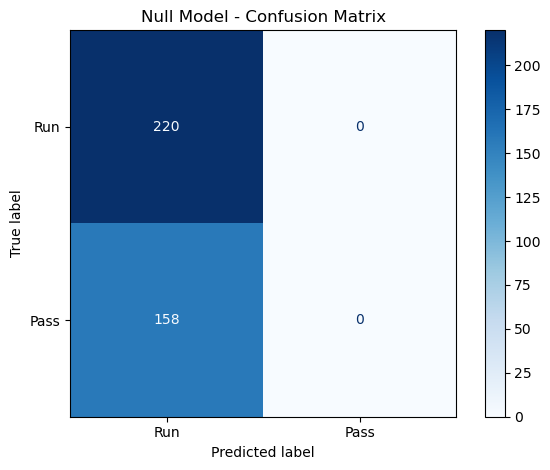

In [81]:
# Evaluate model

# Test accuracy
null_accuracy = accuracy_score(y_test, y_pred_null)
print(f"Null Model Test Accuracy: {null_accuracy:.4f}")

# Null model evaluation
print("Classification report:")
print(classification_report(
    y_test,
    y_pred_null,
    target_names = ["Run", "Pass"],
    zero_division = 0
))

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_null)

ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels = ["Run", "Pass"]
).plot(cmap = "Blues", values_format = "d")

plt.title("Null Model - Confusion Matrix")
plt.tight_layout()
plt.show()

In [82]:
# Store baseline results
results = {
    "Null Model": {
        "Accuracy": accuracy_score(y_test, y_pred_null),
        "Precision": precision_score(y_test, y_pred_null, zero_division = 0),
        "Recall": recall_score(y_test, y_pred_null, zero_division = 0),
        "F1 Score": f1_score(y_test, y_pred_null, zero_division = 0)
    }
}

### Logistic Regression
Baseline multiple logistic regression

This model estimates the probability of a pass occurring based on a linear combination of the predictor varirables. A probability threshold is then used to determine if the play is a pass or a run. This is also known as the sigmoid function. This will be implemented with scikit-learn's `LogisticRegression`.

In [83]:
# Initialize logistic regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        penalty = None,
        max_iter = 3000,
        random_state = RANDOM_STATE
    ))
])

# Fit with training data
logistic_model.fit(X_train, y_train)

# Generate predictions
# Predicted classes 
y_pred_log = logistic_model.predict(X_test)

# Predicted probabilities: returns probability for run and pass for each observation
y_prob_log = logistic_model.predict_log_proba(X_test)[:, 1]

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Accuracy:  0.6402
Precision: 0.5982
Recall:    0.4241
F1 Score:  0.4963
ROC AUC:   0.6522
Classification report:
              precision    recall  f1-score   support

         Run       0.66      0.80      0.72       220
        Pass       0.60      0.42      0.50       158

    accuracy                           0.64       378
   macro avg       0.63      0.61      0.61       378
weighted avg       0.63      0.64      0.63       378



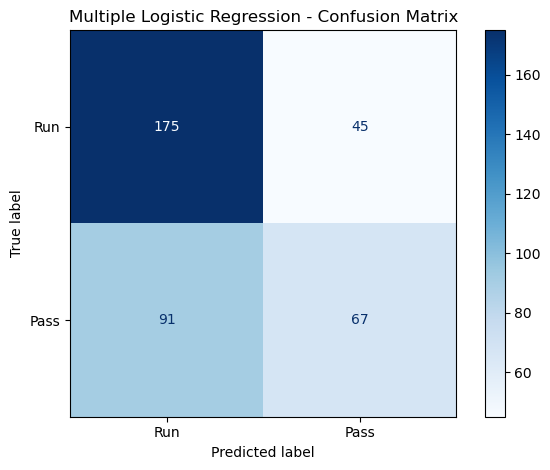

In [84]:
# Evaluate model

log_accuracy = accuracy_score(y_test, y_pred_log)
log_precision = precision_score(y_test, y_pred_log, zero_division=0)
log_recall = recall_score(y_test, y_pred_log, zero_division=0)
log_f1 = f1_score(y_test, y_pred_log, zero_division=0)
log_auc = roc_auc_score(y_test, y_prob_log)

print(f"Accuracy:  {log_accuracy:.4f}")
print(f"Precision: {log_precision:.4f}")
print(f"Recall:    {log_recall:.4f}")
print(f"F1 Score:  {log_f1:.4f}")
print(f"ROC AUC:   {log_auc:.4f}")

print("Classification report:")
print(classification_report(
    y_test,
    y_pred_log,
    labels = [0, 1],
    target_names = ["Run", "Pass"],
    zero_division = 0
))

# Generate confusion matrix
cm_log = confusion_matrix(y_test, y_pred_log)

ConfusionMatrixDisplay(
    confusion_matrix = cm_log,
    display_labels = ["Run", "Pass"]
).plot(cmap = "Blues", values_format = "d")

plt.title("Multiple Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [85]:
# Store results
results["Logistic Regression"] = {
    "Accuracy": log_accuracy,
    "Precision": log_precision,
    "Recall": log_recall,
    "F1 Score": log_f1,
    "ROC AUC": log_auc
}

,Feature,Coefficient,Abs_Coefficient
33,binary__short_yardage,-1.502103,1.502103
35,binary__trailing_late,1.107198,1.107198
19,categorical__down_4,1.021472,1.021472
31,binary__red_zone,-0.906994,0.906994
17,categorical__down_2,-0.711241,0.711241
34,binary__two_minute,0.682634,0.682634
16,categorical__down_1,-0.670407,0.670407
29,binary_missing__missingindicator_prev_call_3,0.570827,0.570827
24,binary_missing__prev_call_1,-0.350410,0.350410
18,categorical__down_3,0.327097,0.327097


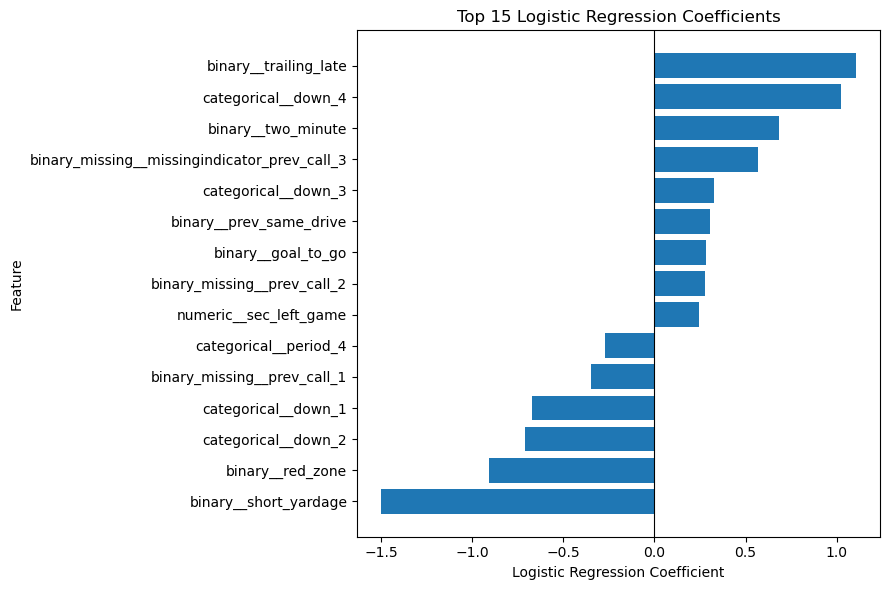

In [86]:
# Extract transformed feature names
feature_names = (
    logistic_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract coefficients
coefficients = logistic_model.named_steps["classifier"].coef_[0]

# Create coefficient dataframe
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient
coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

display(coef_df.head(15))

top_coef = coef_df.head(15).sort_values("Coefficient")

plt.figure(figsize=(9, 6))

plt.barh(
    top_coef["Feature"],
    top_coef["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

These coefficients tell us how each feature is associated with the likelihood of the offense choosing a pass over a run, holding the other features constant. Positive coefficents represent that the feature is associated with a greater likelihood of passing, and negative coefficients with a greater likelihood of running. The largest coefficients are associated with `short_yardage`, `trailing_late`, and `down_4`. 
- `short_yardage`: teams may favor running plays when they only need a few yards for a first down
- `trailing_late`: teams may pass more frequently when trying to catch up
- `down_4`: teams may pass more when they need to convert a fourth down situation

### Lasso Logistic Regression
Using regularization to focus on feature selection

This model uses regularized regression with the L1 loss, specifically to identify which features are most useful for predicting pass or run. Lasso regression can shrink coefficients down to zero, effectively removing them from the model. This will be implemented with scikit-learn's `LogisticRegression`, with inverse regularization hyperarameter C (smaller C for stronger regularization)

In [87]:
# Initialize lasso model
lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        penalty = "l1",
        solver = "saga",
        C = 1.0,
        max_iter = 10000,
        random_state = RANDOM_STATE
    ))
])

# Fit with training data
lasso_model.fit(X_train, y_train)

# Generate predictions
# Predicted classes 
y_pred_lasso = lasso_model.predict(X_test)

# Predicted probabilities: returns probability for run and pass for each observation
y_prob_lasso = lasso_model.predict_log_proba(X_test)[:, 1]

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Accuracy:  0.6349
Precision: 0.5893
Recall:    0.4177
F1 Score:  0.4889
ROC AUC:   0.6535
Classification report:
              precision    recall  f1-score   support

         Run       0.65      0.79      0.72       220
        Pass       0.59      0.42      0.49       158

    accuracy                           0.63       378
   macro avg       0.62      0.60      0.60       378
weighted avg       0.63      0.63      0.62       378



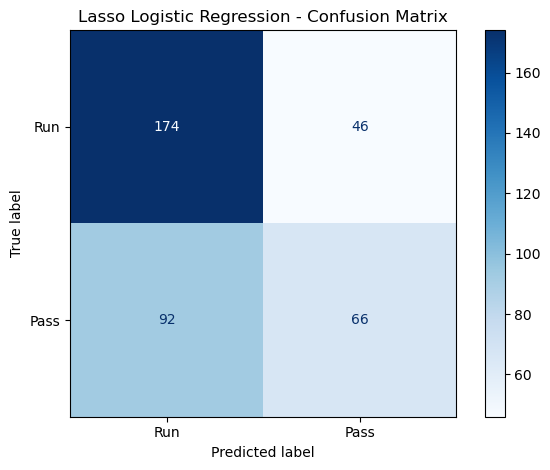

In [88]:
# Evaluate model

lasso_accuracy = accuracy_score(y_test, y_pred_lasso)
lasso_precision = precision_score(y_test, y_pred_lasso, zero_division=0)
lasso_recall = recall_score(y_test, y_pred_lasso, zero_division=0)
lasso_f1 = f1_score(y_test, y_pred_lasso, zero_division=0)
lasso_auc = roc_auc_score(y_test, y_prob_lasso)

print(f"Accuracy:  {lasso_accuracy:.4f}")
print(f"Precision: {lasso_precision:.4f}")
print(f"Recall:    {lasso_recall:.4f}")
print(f"F1 Score:  {lasso_f1:.4f}")
print(f"ROC AUC:   {lasso_auc:.4f}")

print("Classification report:")
print(classification_report(
    y_test,
    y_pred_lasso,
    labels = [0, 1],
    target_names = ["Run", "Pass"],
    zero_division = 0
))

# Generate confusion matrix
cm_log = confusion_matrix(y_test, y_pred_lasso)

ConfusionMatrixDisplay(
    confusion_matrix = cm_log,
    display_labels = ["Run", "Pass"]
).plot(cmap = "Blues", values_format = "d")

plt.title("Lasso Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [89]:
# Store results
results["Lasso Logistic Regression"] = {
    "Accuracy": lasso_accuracy,
    "Precision": lasso_precision,
    "Recall": lasso_recall,
    "F1 Score": lasso_f1,
    "ROC AUC": lasso_auc
}

In [90]:
# Extract transformed feature names
feature_names_lasso = (
    lasso_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract coefficients
coefficients_lasso = lasso_model.named_steps["classifier"].coef_[0]

# Create coefficient dataframe
coef_df_lasso = pd.DataFrame({
    "Feature": feature_names_lasso,
    "Coefficient": coefficients_lasso
})

# Sort by absolute coefficient
coef_df_lasso["Abs_Coefficient"] = coef_df_lasso["Coefficient"].abs()

# Identify selected and eliminated features
coef_df_lasso["Selected"] = (coef_df_lasso["Coefficient"] != 0)

coef_df_lasso = coef_df_lasso.sort_values(
    "Abs_Coefficient",
    ascending=False
)

display(coef_df_lasso)

total_features = len(coef_df_lasso)

selected_features = coef_df_lasso[
    coef_df_lasso["Selected"]
]

excluded_features = coef_df_lasso[
    ~coef_df_lasso["Selected"]
]

print(f"Total features: {total_features}")
print(f"Selected features: {len(selected_features)}")
print(f"Excluded features: {len(excluded_features)}")
print(
    f"Percentage retained: "
    f"{len(selected_features) / total_features:.1%}"
)

print("\nSelected features:")
display(selected_features[["Feature", "Coefficient", "Abs_Coefficient"]])

,Feature,Coefficient,Abs_Coefficient,Selected
33,binary__short_yardage,-1.376915,1.376915,True
35,binary__trailing_late,0.994349,0.994349,True
31,binary__red_zone,-0.818162,0.818162,True
19,categorical__down_4,0.760474,0.760474,True
34,binary__two_minute,0.621067,0.621067,True
17,categorical__down_2,-0.592282,0.592282,True
16,categorical__down_1,-0.554195,0.554195,True
29,binary_missing__missingindicator_prev_call_3,0.488131,0.488131,True
23,categorical__period_4,-0.361149,0.361149,True
18,categorical__down_3,0.345490,0.345490,True


Total features: 38
Selected features: 30
Excluded features: 8
Percentage retained: 78.9%

Selected features:


,Feature,Coefficient,Abs_Coefficient
33,binary__short_yardage,-1.376915,1.376915
35,binary__trailing_late,0.994349,0.994349
31,binary__red_zone,-0.818162,0.818162
19,categorical__down_4,0.760474,0.760474
34,binary__two_minute,0.621067,0.621067
17,categorical__down_2,-0.592282,0.592282
16,categorical__down_1,-0.554195,0.554195
29,binary_missing__missingindicator_prev_call_3,0.488131,0.488131
23,categorical__period_4,-0.361149,0.361149
18,categorical__down_3,0.345490,0.345490


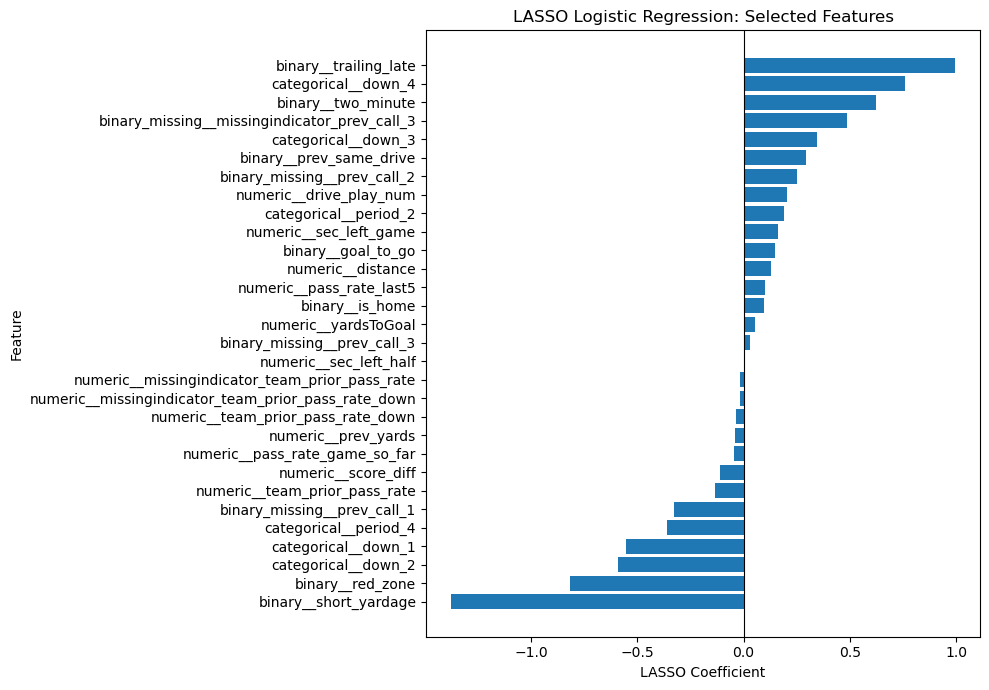

In [91]:
# Visualize selected features
selected_plot = selected_features.sort_values("Coefficient")

plt.figure(figsize = (10, 7))

plt.barh(
    selected_plot["Feature"],
    selected_plot["Coefficient"]
)

plt.axvline(0, color = "black", linewidth=0.8)

plt.xlabel("LASSO Coefficient")
plt.ylabel("Feature")
plt.title("LASSO Logistic Regression: Selected Features")

plt.tight_layout()
plt.show()

The model removed 8 of the 38 transformed features: `first_play_of_game`, `missingindicator_prev_call_2`, `missingindicator_prev_yards`, `period_1`, `missingindicator_prev_call_1`, `missingindicator_pass_rate_game_so_far`, `period_3`, and `missingindicator_pass_rate_last5`.

In the model, it shows that game situation is highly predictive, as seen in the relatively large coefficients for attributes like `short_yardage`, `trailing_late`, `red_zone`, and `two_minute`. This suggests that the situational context is important in predicting play selection.

All four `down` categories also have nonzero coefficients, suggesting that down-specific information also contributes to the prediction, even when included with other game situation variables. 

Play history has also shown to be helpful in this model, as seen through selected features such as `prev_same_drive`, `prev_call_1`, and `prev_call_2`.

## Results

In [92]:
# Convert results dictionary to DataFrame
results_df = pd.DataFrame(results).T

# Display results
display(results_df.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Null Model,0.5820,0.0000,0.0000,0.0000,NaN
Logistic Regression,0.6402,0.5982,0.4241,0.4963,0.6522
Lasso Logistic Regression,0.6349,0.5893,0.4177,0.4889,0.6535
